In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
titanic_df = pd.read_csv('titanic.csv')
titanic_df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [5]:
titanic_df.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')

In [ ]:
titanic_df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [6]:
titanic_df["Embarked"].value_counts()

Embarked
S    644
C    168
Q     77
Name: count, dtype: int64

In [11]:
titanic_df["embarked_new"]=np.where(titanic_df["Embarked"]=="C", "Cherbourg", 
                                     np.where(titanic_df["Embarked"]=="Q", "Queenstown", 
                                              "Southampton"))

In [12]:
titanic_df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,embarked_new
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,Southampton
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,Cherbourg
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,Southampton
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,Southampton
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,Southampton


In [13]:
# How would we process mr and mrs, etc in the Name column?
titanic_df["mr_mrs"] = titanic_df["Name"].str.split(",").str[1].str.split(".").str[0].str.strip()

titanic_df["mr_mrs"].value_counts()

mr_mrs
Mr              517
Miss            182
Mrs             125
Master           40
Dr                7
Rev               6
Mlle              2
Major             2
Col               2
the Countess      1
Capt              1
Ms                1
Sir               1
Lady              1
Mme               1
Don               1
Jonkheer          1
Name: count, dtype: int64

In [15]:
titanic_df["Sex"].value_counts()

Sex
male      577
female    314
Name: count, dtype: int64

# Basic Plots

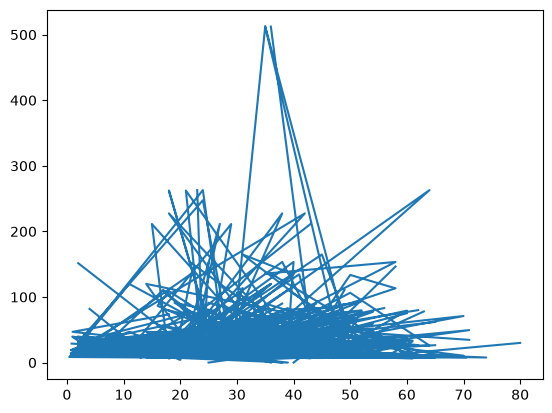

In [16]:
# x-axis, y-axis
plt.plot(titanic_df["Age"], titanic_df["Fare"])

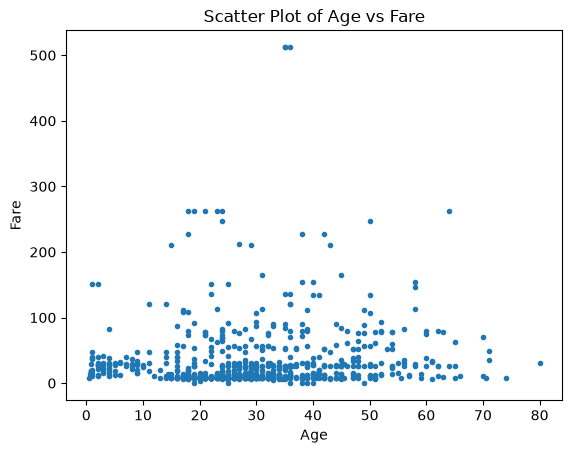

Correlation between Age and Fare: 0.09606669176903894


In [20]:
plt.plot(titanic_df["Age"], titanic_df["Fare"], ".")
plt.xlabel("Age")
plt.ylabel("Fare")
plt.title("Scatter Plot of Age vs Fare")
plt.show()

correlation = titanic_df["Age"].corr(titanic_df["Fare"])
print(f"Correlation between Age and Fare: {correlation}")

# Histograms

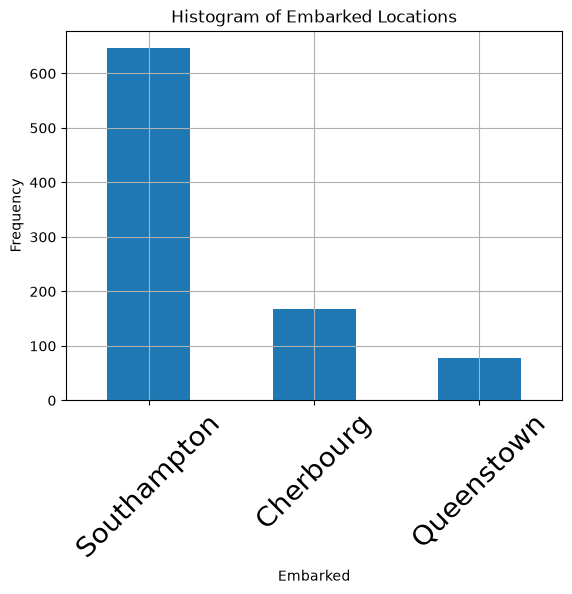

In [24]:
# histograms show us frequency of whatever column we pass in
# in other words: how many records have that value

embarked_count = titanic_df["embarked_new"].value_counts()
# plt.bar(embarked_count.index, embarked_count.values)
embarked_count.plot(kind="bar")
plt.xlabel("Embarked")
plt.ylabel("Frequency")
plt.grid()
plt.xticks(fontsize=20, rotation=45)
plt.title("Histogram of Embarked Locations")
plt.show()

# Pie Charts

In [26]:
agg_gender = titanic_df["Sex"].groupby(titanic_df["Sex"]).count()
agg_gender

Sex
female    314
male      577
Name: Sex, dtype: int64

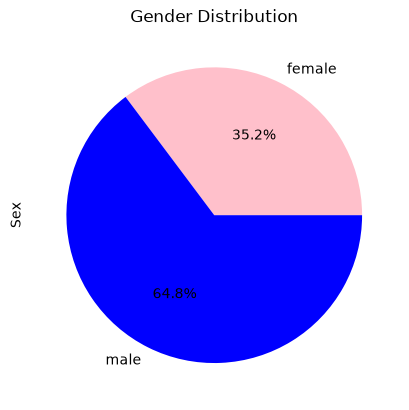

In [28]:
colors = ["pink", "blue"]
agg_gender.plot(kind="pie", colors=colors, autopct="%1.1f%%")
plt.title("Gender Distribution")
plt.show()


In [30]:
%pip install seaborn

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)

[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [33]:
titanic_df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,embarked_new,mr_mrs
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,Southampton,Mr
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,Cherbourg,Mrs
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,Southampton,Miss
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,Southampton,Mrs
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,Southampton,Mr


# Boxplots

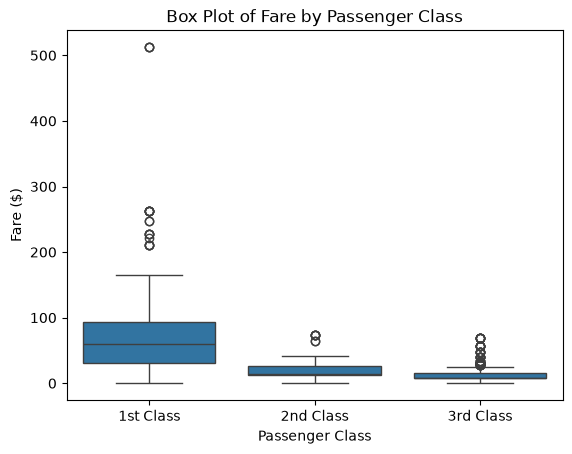

In [40]:
import seaborn as sns
sns.boxplot(data= titanic_df, x="Pclass", y="Fare")
plt.xlabel("Passenger Class")
plt.ylabel("Fare ($)")
plt.title("Box Plot of Fare by Passenger Class")
plt.xticks([0,1,2], ["1st Class", "2nd Class", "3rd Class"])
# plt.tight_layout(pad=2.0)
plt.show()

# One-Way ANOVA

In [ ]:
#Null hypothesis: All three classes have the same mean age.
#Alternative hypothesis: At least one class has a different mean age.
from scipy.stats import f_oneway

#remove na values from age
titanic_df = titanic_df.dropna(subset=["Age"])

first_class = titanic_df.loc[titanic_df["Pclass"] == 1, "Age"]
second_class = titanic_df.loc[titanic_df["Pclass"] == 2, "Age"]
third_class = titanic_df.loc[titanic_df["Pclass"] == 3, "Age"]

# high level statistics
print(titanic_df.groupby("Pclass")["Age"].agg(["mean", "std", "count"]))

# ANOVA test
f_stat, p_value = f_oneway(first_class, second_class, third_class)

df_between = 3-1
df_within = len(titanic_df) - 3

print(f"df_between: {df_between}")
print(f"df_within: {df_within}")
print(f"F-statistic=df_between/df_within ({df_between}/{df_within}) = {f_stat}")
# if the F-statistic is large and the p-value is small, we reject the null hypothesis
# the F-statistic being large indicates the group means are different
print(f"p-value: {p_value}")

if p_value < 0.05:
    print("Reject the null hypothesis: At least one class has a different mean age.")
else:
    print("Fail to reject the null hypothesis: All classes have the same mean age.")



             mean        std  count
Pclass                             
1       38.233441  14.802856    186
2       29.877630  14.001077    173
3       25.140620  12.495398    355
F-statistic: 57.44348434067623
p-value: 7.487984171957403e-24


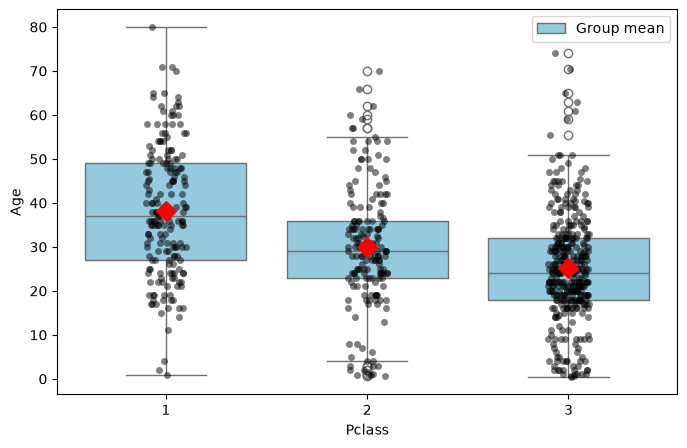

In [ ]:
fig, ax = plt.subplots(figsize=(8,5))

sns.boxplot(
    data=titanic_df,
    x="Pclass",
    y="Age",
    color = "skyblue",
    ax=ax
)

sns.stripplot(
    data=titanic_df,
    x="Pclass",
    y="Age",
    color="black",
    alpha=0.5,
    jitter=True,
    ax=ax
)

# mark the actual means ANOVA is comparing

means = titanic_df.groupby("Pclass")["Age"].mean()
ax.scatter(x=[0,1,2], y=means.values, marker= "D", color="red", s=100, label = "Group mean", zorder=5)
#diamonds represent the mean whereas the middle lines of the boxplot represent the median

#show a legend for the red diamond

ax.legend(["Group mean"])
plt.show()